<a href="https://colab.research.google.com/github/IlhamDharm/244107020220-machine-learning/blob/main/TG9_244107020220_ILHAM_DHARMA_ATMAJA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Klasifikasi 2**

# **`Praktikum 1 - Klasifikasi SVM dengan Data Dummy Linier`**



---


Langkah 1 - Import Library

In [47]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns

Langkah 2 - Membuat Data Dummy

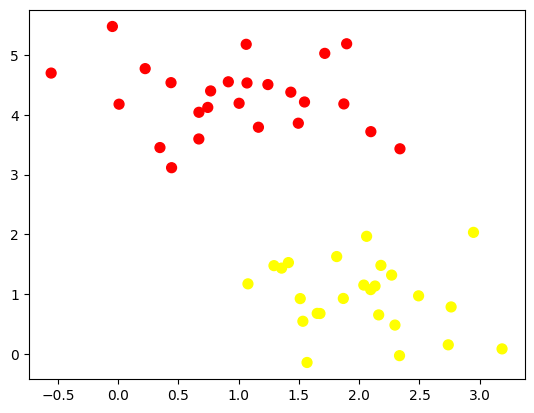

In [48]:
	from sklearn.datasets import make_blobs
	X, y = make_blobs(n_samples=50, centers=2,
	                  random_state=0, cluster_std=0.60)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Buat Ilustrasi Garis Pemisah

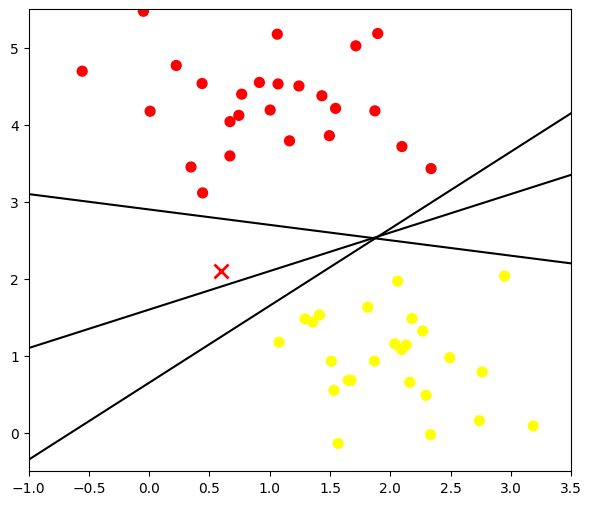

In [49]:
xfit = np.linspace(-1, 3.5)

plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1.0, 3.5)
plt.ylim(-0.5, 5.5)
plt.show()

Langkah 4 - Ilustrasi Margin

(-1.0, 3.5)

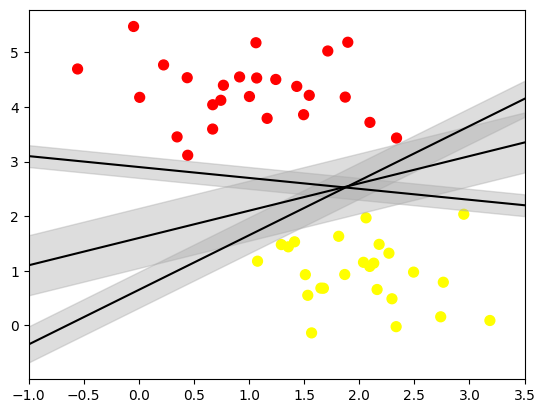

In [50]:
	xfit = np.linspace(-1, 3.5)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

	for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
	    yfit = m * xfit + b
	    plt.plot(xfit, yfit, '-k')
	    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
	                     color='#AAAAAA', alpha=0.4)

	plt.xlim(-1, 3.5)

Langkah 5 - Fitting Model

In [51]:
	from sklearn.svm import SVC # "Support vector classifier"
	model = SVC(kernel='linear', C=1E10)
	model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

fungsi untuk membantu visualisasi hasil fit model

In [52]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

 plotting

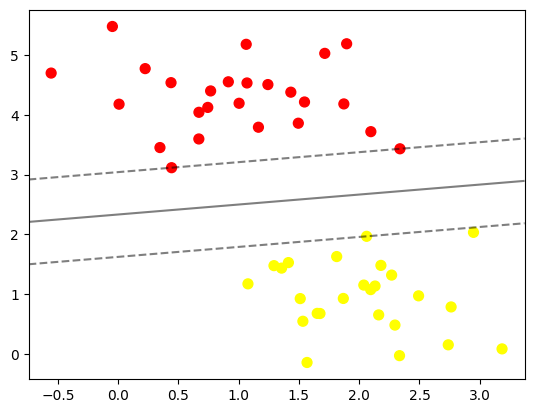

In [53]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(model)

In [54]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

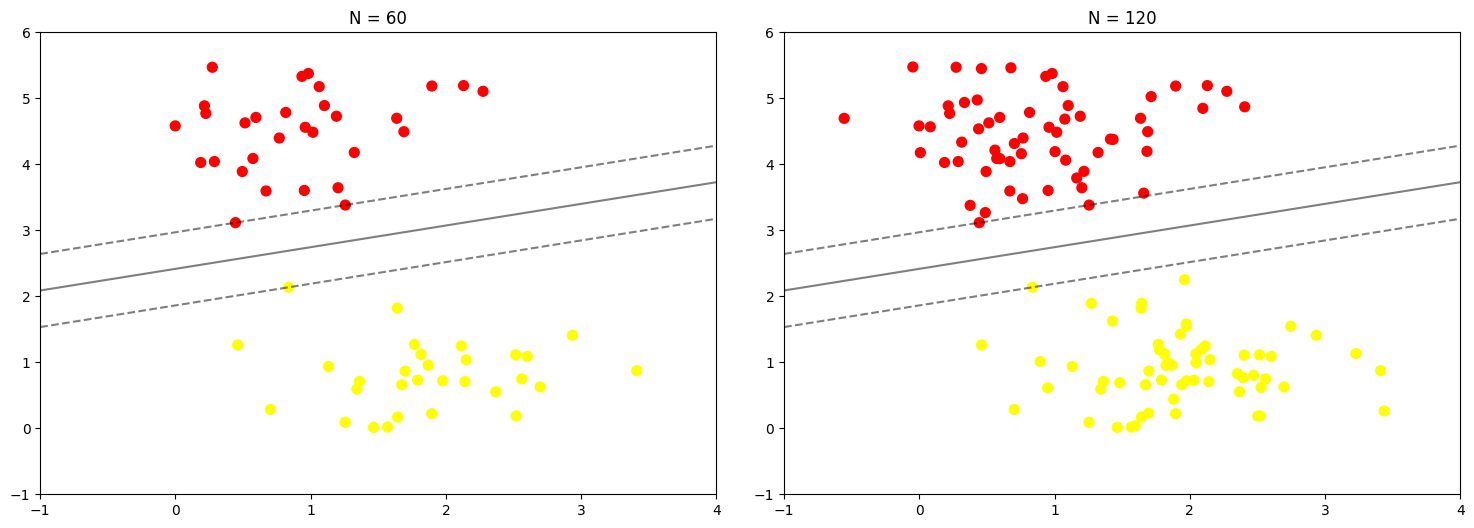

In [55]:
	def plot_svm(N=10, ax=None):
	    X, y = make_blobs(n_samples=200, centers=2,
	                      random_state=0, cluster_std=0.60)
	    X = X[:N]
	    y = y[:N]
	    model = SVC(kernel='linear', C=1E10)
	    model.fit(X, y)

	    ax = ax or plt.gca()
	    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    ax.set_xlim(-1, 4)
	    ax.set_ylim(-1, 6)
	    plot_svc_decision_function(model, ax)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
	for axi, N in zip(ax, [60, 120]):
	    plot_svm(N, axi)
	    axi.set_title('N = {0}'.format(N))

In [56]:
	# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

	from ipywidgets import interact, fixed
	interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>



---

# **`Praktikum 2 - Klasifikasi SVM dengan Data Dummy Non-Linier`**

Langkah 1 - Ilustrasi Data Non-Linier

Langkah 1a - Import Library

In [57]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

Langkah 1b - Buat Kembali Fungsi Plotting

In [58]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Langkah 1c - Buat Data Dummy Non-Linier

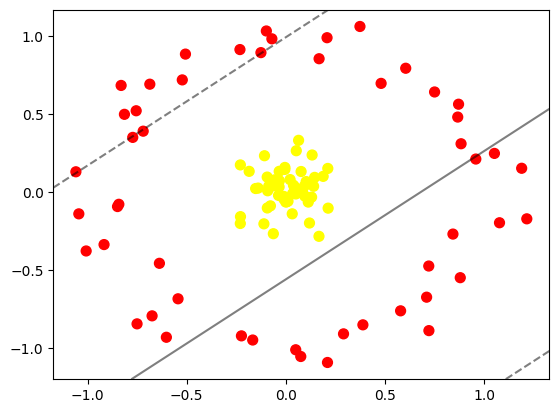

In [59]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

In [60]:
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

r = np.exp(-(X ** 2).sum(1))

def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')

interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180),
         X=fixed(X), y=fixed(y))

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 1.18604054e-01, -1.99936833e-01],
       [-8.67772781e-02,  3.64713883e-02],
       [-1.09397609e-02, -2.93316375e-02],
       [-7.72256323e-01,  3.49295114e-01],
       [ 6.03662358e-01,  7.92718034e-01],
       [-8.30822432e-01,  6.82426851e-01],
       [ 8.65839902e-01,  4.79585188e-01],
       [-9.21918119e-02,  6.90091840e-03],
       [-2.24412296e-01, -9.23755406e-01],
       [ 3.33393570e-02, -1.19101651e-02],
       [-6.36266466e-02, -2.68575686e-01],
       [-2.29797890e-01,  1.72627593e-01],
       [ 8.40418488e-02, -3.58224678e-03],
       [ 1.01915831e-01,  6.58005312e-02],
       [-6.54017283e-02,  3.80087799e-02],
       [-8.42319190e-01, -7.98342700e-02],
       [-7.50535569e-01, -8.46741795e-01],
       [ 8.78555270e-01, -5.50614153e-01],
       [ 5.20554538e-02,  2.63645048e-01],
       [ 3.72949950e-01,  1.06062430e+00],
       [-6.02727277e-01, -9.32762217e-01],
       [-1.26142979e-01,  8.92880112e-01],
       [ 7.49128837e-01,  6.40533849e-01],
       [-3.74602272e-02, -2.28157643e-02],
       [ 7.63094273e-02,  1.30418188e-01],
       [ 4.92997264e-02, -1.01293798e+00],
       [-5.22551438e-01,  7.18010767e-01],
       [ 3.15903616e-02, -1.40943015e-01],
       [-6.37823670e-01, -4.58410552e-01],
       [ 9.49943171e-02, -2.73484318e-02],
       [-1.67566598e-01, -9.50439195e-01],
       [ 1.87485563e-01,  9.92698937e-02],
       [ 2.10947698e-01,  1.50088173e-01],
       [-8.48939654e-01, -9.43360949e-02],
       [-3.31100987e-02,  7.10046943e-02],
       [ 1.03206907e-02, -6.00966120e-02],
       [ 1.31828642e-01,  2.36317678e-01],
       [ 8.82581650e-01,  3.08415744e-01],
       [ 1.05071165e+00,  2.46477904e-01],
       [-6.74761327e-01, -7.95417740e-01],
       [-1.52835989e-01,  2.12359609e-02],
       [-1.00701854e+00, -3.79259679e-01],
       [-5.68346214e-02,  7.68719042e-02],
       [-1.05877279e+00,  1.28588716e-01],
       [ 1.21392878e+00, -1.73105390e-01],
       [-1.11585484e-02, -4.53554985e-02],
       [-1.11135207e-01, -2.05283125e-01],
       [ 1.18807675e+00,  1.51179263e-01],
       [ 6.36898719e-02,  3.30420854e-01],
       [ 4.79582539e-01,  6.95691310e-01],
       [-3.40514765e-02,  1.31563008e-01],
       [-1.40369880e-01,  2.40079036e-02],
       [-8.14116254e-01,  4.97180857e-01],
       [-9.39518926e-02, -1.03405830e-01],
       [ 2.90165124e-01, -9.10911158e-01],
       [-9.16861539e-01, -3.38228897e-01],
       [ 8.69992498e-01,  5.62007567e-01],
       [ 4.96862281e-02, -1.35621468e-02],
       [-1.04399352e+00, -1.41194034e-01],
       [ 2.09357049e-01, -1.09447466e+00],
       [ 2.12583197e-01, -1.04635403e-01],
       [-5.06583493e-01,  8.83446138e-01],
       [ 1.39475707e-01,  3.59330509e-02],
       [-2.29205003e-01, -1.59067910e-01],
       [-5.31536805e-03,  1.56556544e-01],
       [ 8.41640482e-01, -2.70875865e-01],
       [-7.19631634e-01,  3.89066558e-01],
       [ 5.77854220e-01, -7.63194526e-01],
       [-1.85433023e-01,  1.31512517e-01],
       [ 2.08670834e-02,  7.85107005e-02],
       [-7.09520506e-02,  9.81505397e-01],
       [-6.86177503e-01,  6.90458633e-01],
       [ 9.56962862e-01,  2.10352938e-01],
       [-7.54907832e-01,  5.20017918e-01],
       [ 7.08965847e-01, -6.75663691e-01],
       [ 1.44599990e-01,  9.27838038e-02],
       [ 1.07635285e+00, -1.98300816e-01],
       [ 4.32580807e-02,  3.17895121e-02],
       [-9.88176192e-02,  1.03174099e+00],
       [-1.07766951e-03, -6.50602229e-02],
       [-9.45442576e-02,  9.46998845e-02],
       [ 1.29249066e-01, -3.39601754e-02],
       [ 1.67027568e-01,  8.53781912e-01],
       [-7.83057867e-02, -8.98251594e-02],
       [ 3.15151317e-03, -6.42143123e-02],
       [-2.30076796e-01, -2.02989407e-01],
       [-1.08237449e-01,  2.31620536e-01],
       [ 1.66428553e-01, -2.85309314e-01],
       [ 2.07077064e-01,  9.88565084e-01],
       [-5.43954391e-01, -6.86020329e-01],
       [ 9.27114444e-02,  3.68265396e-02],
       [ 1.12403970e-01, -6.57140167e-02

In [61]:
!pip install ipywidgets

Langkah 2 - Fitting Model

In [62]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

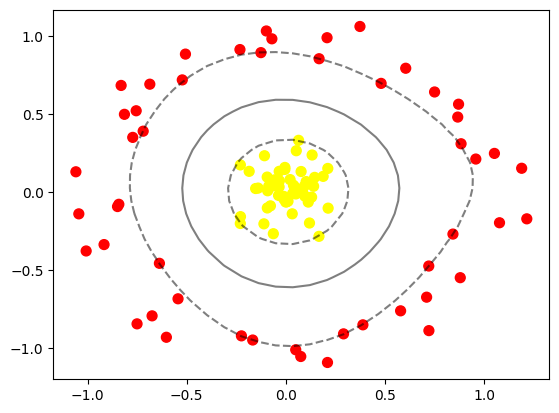

In [63]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf)
	plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
	            s=300, lw=1, facecolors='none')



---

# **`Praktikum 3 - SVM Data Overlapping`**



Langkah 1 - Import Library dan Buat Fungsi Plotting

In [64]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC
	from sklearn.datasets import make_blobs

In [65]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

Langkah 2 - Buat Data Dummy

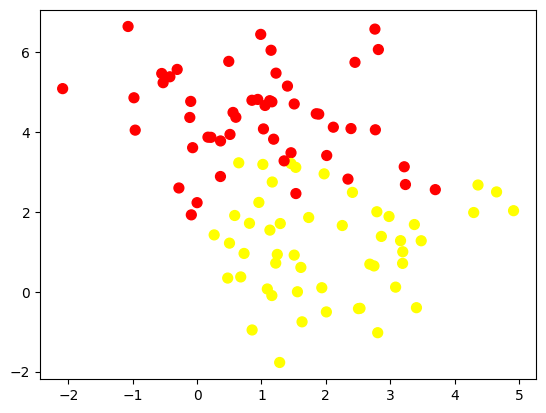

In [66]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=1.2)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

Langkah 3 - Analisis Dampak Tunning

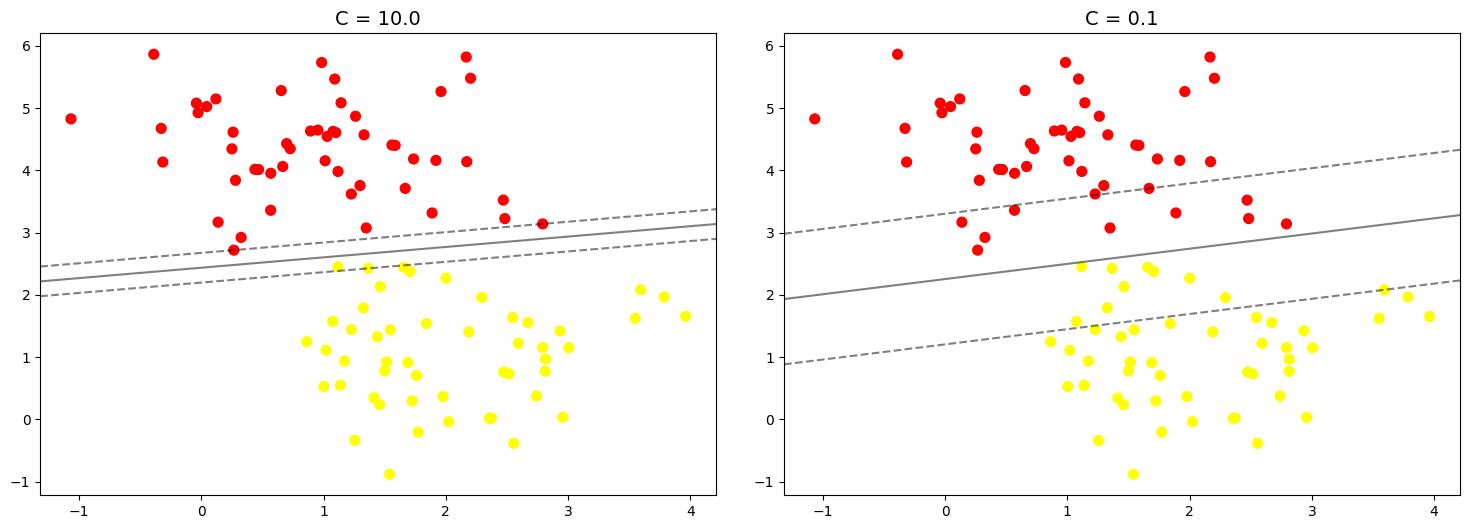

In [67]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=0.8)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

	for axi, C in zip(ax, [10.0, 0.1]):
	    model = SVC(kernel='linear', C=C).fit(X, y)
	    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    plot_svc_decision_function(model, axi)
	    axi.scatter(model.support_vectors_[:, 0],
	                model.support_vectors_[:, 1],
	                s=300, lw=1, facecolors='none');
	    axi.set_title('C = {0:.1f}'.format(C), size=14)



---



# **`Praktikum 4 - Klasifikasi Citra Wajah`**

Langkah 0 - Unduh Dataset

In [68]:
	from sklearn.datasets import fetch_lfw_people
	faces = fetch_lfw_people(min_faces_per_person=60)
	print(faces.target_names)
	print(len(faces.target_names))
	print(faces.images.shape)


['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


Langkah 1 - Inspeksi Citra Wajah

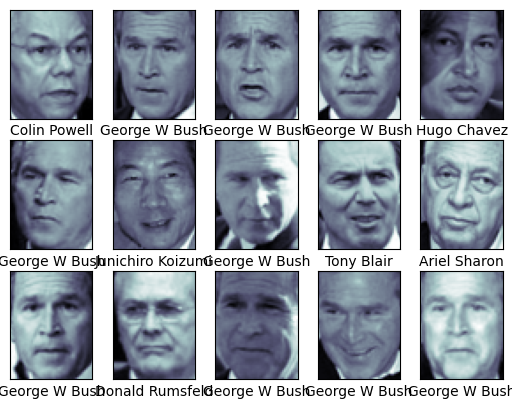

In [69]:
	# contoh wajah yang digunakan
	from matplotlib import pyplot as plt

	fig, ax = plt.subplots(3, 5)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(faces.images[i], cmap='bone')
	    axi.set(xticks=[], yticks=[],
	            xlabel=faces.target_names[faces.target[i]])

Langkah 2 - Pra Pengolahan Data

In [70]:
	from sklearn.svm import SVC
	from sklearn.decomposition import PCA as RandomizedPCA
	from sklearn.pipeline import make_pipeline

	pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
	svc = SVC(kernel='rbf', class_weight='balanced')

	# Pipeline digunakan untuk melakukan proses secara bertahap dalam
	# 1 eksekusi fungsi secara langsung
	model = make_pipeline(pca, svc)

Langkah 3 - Split Data

In [71]:
	# pemisahan data training dan data testing

	from sklearn.model_selection import train_test_split
	Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

Langkah 4 - Pembuatan Model + Tunning

In [72]:
	from sklearn.model_selection import GridSearchCV
	param_grid = {'svc__C': [1, 5, 10, 50],
	              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
	grid = GridSearchCV(model, param_grid)

	%time grid.fit(Xtrain, ytrain)
	print(grid.best_params_)
	print(grid.best_score_)

CPU times: user 2min, sys: 152 ms, total: 2min 1s
Wall time: 1min 36s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [73]:
	model = grid.best_estimator_
	yfit = model.predict(Xtest)

Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

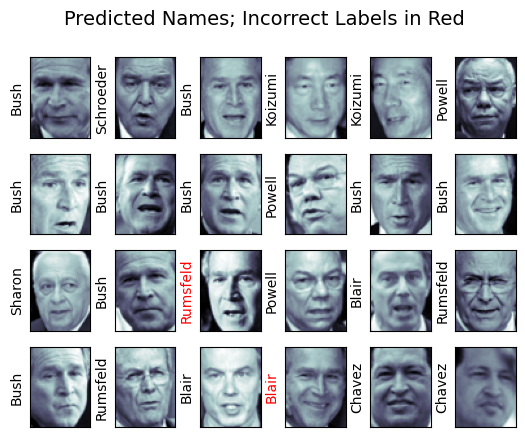

In [74]:
	# hasil label pada data testing

	fig, ax = plt.subplots(4, 6)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
	    axi.set(xticks=[], yticks=[])
	    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
	                   color='black' if yfit[i] == ytest[i] else 'red')
	fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

Langkah 6 - Cek Performansi

In [75]:
	from sklearn.metrics import classification_report
	print(classification_report(ytest, yfit,
	                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



Text(113.92222222222219, 0.5, 'predicted label')

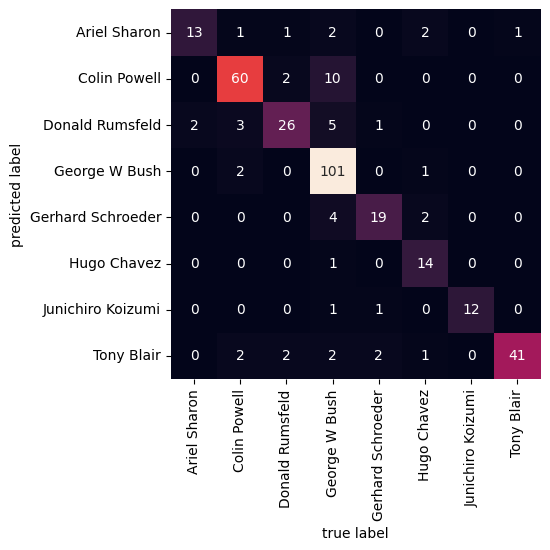

In [76]:
	# bentuk confusion matrix
	from sklearn.metrics import confusion_matrix
	import seaborn as sns

	mat = confusion_matrix(ytest, yfit)
	sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
	            xticklabels=faces.target_names,
	            yticklabels=faces.target_names)
	plt.xlabel('true label')
	plt.ylabel('predicted label')



---


# **`Praktikum 5 - Klasifikasi Citra Siang dan Malang`**

Langkah 0 - Import Library

In [77]:
	# Import Required Libraries
	from pathlib import Path
	import matplotlib.image as mpimg
	import matplotlib.pyplot as plt
	import cv2
	import random
	import numpy as np
	import pandas as pd

In [78]:
	# Image directories
	train_dir = "images/training/"
	test_dir = "images/test/"

Langkah 1 - Load Data dan Visualisasikan

In [79]:
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    dirs = p.glob('*')

	    img_list = []

	    for dir in dirs:
	        label = str(dir).split('/')[-1]
	        for file in dir.glob('*.jpg'):
	            img = mpimg.imread(file)

	            if not img is None:
	                img_list.append((img, label))

	    return img_list

In [80]:
	# Load training data
	train_img = load_dataset(train_dir)

In [81]:
	# Check the first data
	# It should be a tuple consist of arrays of image and image labels
	train_img[0]

(array([[[151, 159, 162],
         [150, 158, 161],
         [148, 156, 159],
         ...,
         [ 37,  42,  46],
         [ 39,  44,  48],
         [ 40,  45,  49]],
 
        [[151, 159, 162],
         [151, 159, 162],
         [150, 158, 161],
         ...,
         [ 29,  34,  38],
         [ 29,  34,  38],
         [ 36,  41,  45]],
 
        [[152, 160, 163],
         [152, 160, 163],
         [152, 160, 163],
         ...,
         [ 31,  36,  40],
         [ 32,  37,  41],
         [ 37,  42,  46]],
 
        ...,
 
        [[  1,   1,   1],
         [  1,   1,   1],
         [  1,   1,   1],
         ...,
         [ 19,  14,  10],
         [ 19,  14,  10],
         [ 20,  15,  11]],
 
        [[  1,   1,   1],
         [  1,   1,   1],
         [  1,   1,   1],
         ...,
         [ 12,   7,   3],
         [ 13,   8,   4],
         [ 19,  14,  10]],
 
        [[  1,   1,   1],
         [  1,   1,   1],
         [  1,   1,   1],
         ...,
         [  8,   3,   0],
  

In [82]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_img))

	# Check img size
	print(f'Image {pick_random}')
	print(train_img[pick_random][0].shape)

Image 63
(469, 640, 3)


In [83]:
	# Function to Visualize
	def random_img_viz(img_list):
	    rand_num = np.random.randint(0, len(img_list))

	    img = img_list[rand_num][0]
	    label = img_list[rand_num][1]
	    label_str = 'day' if label == 1 else 'night'

	    plt.imshow(img)
	    print(f'Shape\t: {img.shape}')
	    print(f'Label\t: {label}')

Shape	: (700, 1280, 3)
Label	: day


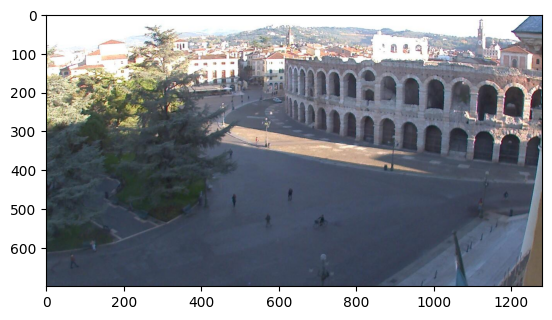

In [84]:
random_img_viz(train_img)

Shape	: (458, 800, 3)
Label	: day


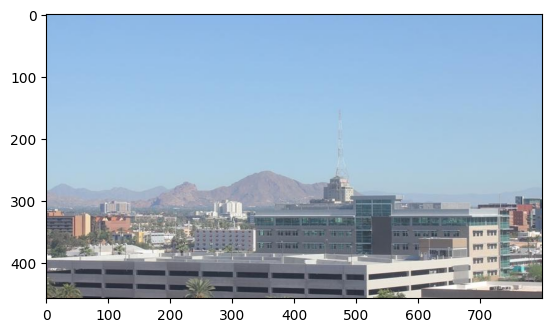

In [85]:
random_img_viz(train_img)

Langkah 3 - Pra Pengolahan Data

In [86]:
	def standarized_input(image):
	    # resize to w: 1100, h:600
	    std_img = cv2.resize(image, (1100,600))

	    return std_img

In [87]:
	def label_encoder(label):
	    # Encode the label
	    # day as 1; night as 0
	    num_val = 0

	    if(label == 'day'):
	        num_val = 1

	    return num_val

In [88]:
	def preprocess(img_list):
	    std_img_list = []

	    for item in img_list:
	        image = item[0]
	        label = item[1]

	        # Standarized the image
	        std_img = standarized_input(image)

	        # Create the label
	        img_label = label_encoder(label)

	        std_img_list.append((std_img, img_label))

	    return std_img_list

In [89]:
train_std_img_list = preprocess(train_img)

In [90]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_std_img_list))

	# Check img size
	print(f'Image {pick_random}')
	print(train_std_img_list[pick_random][0].shape)

Image 55
(600, 1100, 3)


Langkah 4 - Ekstraksi Fitur

In [91]:
	# Get feature based on average brightness using HSV colorspace
	def avg_brightness(image):
	    # Convert image to HSV
	    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

	    # Calculate the avg of brightness
	    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
	    area = image.shape[0] * image.shape[1]
	    avg = sum_brightness / area

	    return avg

Image 42
Avg Brighness: 38.4007


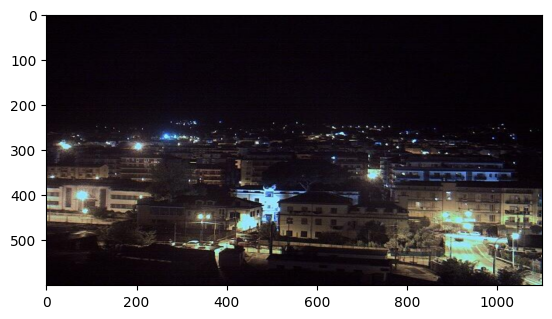

In [92]:
	# Check on random image
	rand_img = np.random.randint(0, len(train_std_img_list))

	feature_img = train_std_img_list[rand_img][0]

	avg_img = avg_brightness(feature_img)

	print(f'Image {rand_img}')
	print(f'Avg Brighness: {avg_img:.4f}')
	plt.imshow(feature_img)

Langkah 5 - Klasifikasi dengan Metode Threshold

In [93]:
	def predict_label(img, threshold):
	    # Computer average brightness
	    avg = avg_brightness(img)
	    pred = 0

	    # Predict the label based on user defined threshold
	    if avg > threshold:
	        pred = 1

	    return pred

Image 125
Actual label: 1
Predicted label: 1


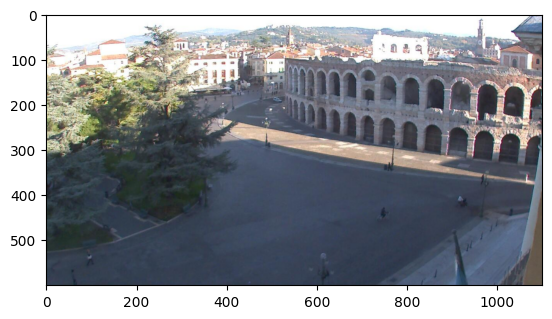

In [94]:
	# Test the classifier on train data
	rand_img = np.random.randint(0, len(train_std_img_list))

	pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

	# Evaluate
	print(f'Image {rand_img}')
	print(f'Actual label: {train_std_img_list[rand_img][1]}')
	print(f'Predicted label: {pred}')
	plt.imshow(train_std_img_list[rand_img][0])

Langkah 6 - Evaluasi Manual

In [95]:
	def evaluate(img_list, threshold):
	    miss_labels = []

	    for file in img_list:
	        # Get the ground truth / correct label
	        img = file[0]
	        label = file[1]

	        # Get prediction
	        pred_label = predict_label(img, threshold)

	        # Compare ground truth and pred
	        if pred_label != label:
	            miss_labels.append((img, pred_label, label))

	    total_img = len(img_list)
	    corr_pred = total_img - len(miss_labels)
	    accuracy = corr_pred / total_img

	    print(f'Accuracy: {accuracy:.4f}')

In [96]:
	# Evaluate on train data
	evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [97]:
	# Evaluate on test data

	# Load test data
	test_img = load_dataset(test_dir)

	# Preprocess
	test_std_img_list = preprocess(test_img)

	# Predict
	evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688




---
# **Klasifikasi dengan SVM**

mencoba menggunakan model SVM untuk proses klasifikasi. Seluruh langkah yang digunakan serupa, kita hanya mengubah mulai langkah ke-4.


Langkah 4 Alternatif - Membuat Feature Vectors

In [98]:
	# Create function to extract feature for every images and stored in tabular data
	# Stored in Pandas dataframe
	def extract_avg_bright_feature(img_list):
	    avg_list = []
	    labels = []

	    for img in img_list:
	        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
	        img_label = img[1] # Get the image label

	        avg_list.append(img_avg)
	        labels.append(img_label)

	    # Stack data in columcular way
	    data = np.column_stack((avg_list, labels))
	    # Create a Pandas dataframe
	    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

	    return df

In [99]:
	# Extract feature on train data
	train_avg_img = extract_avg_bright_feature(train_std_img_list)
	print(f'Shape: {train_avg_img.shape}')
	train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,54.999277,0.0
1,25.731924,0.0
2,25.234265,0.0
3,36.167309,0.0
4,95.862627,0.0


In [100]:
	# Do the same thing on test data
	test_avg_img = extract_avg_bright_feature(test_std_img_list)
	print(f'Shape: {test_avg_img.shape}')
	test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,13.861829,0.0
1,13.861638,0.0
2,88.064115,0.0
3,37.642245,0.0
4,111.826289,0.0


Langkah 5 - Buat Model SVM

In [101]:
	# import requied library
	from sklearn.svm import SVC

	# Split data and label
	X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
	y_train = train_avg_img.iloc[:,1]
	X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
	y_test = test_avg_img.iloc[:,1]

	model = SVC()
	model.fit(X_train, y_train)

SVC()

Langkah 6 - Evaluasi

In [102]:
	from sklearn.metrics import accuracy_score

	# Make a prediction on train data
	y_train_pred = model.predict(X_train)

	# Get the accuracy on train data
	acc_train = accuracy_score(y_train, y_train_pred)

	# Make a prediction on test data
	y_test_pred = model.predict(X_test)

	# Get the accuracy on test data
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print Eval Result
	print(f'Accuracy on train: {acc_train}')
	print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


# **`Tugas Praktikum`**





`Soal 1: Klasifikasi SVM pada Dataset`

In [105]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Load Data (arahkan ke folder sample_data)
df = pd.read_csv('sample_data/voice.csv')

# 2. Pisahkan Fitur (X) dan Target (y) serta Encoding Label
X = df.drop('label', axis=1)
le = LabelEncoder()
y = le.fit_transform(df['label'])

# 3. Konfigurasi Split dan Kernel
splits = {
    '70:30': 0.3,
    '80:20': 0.2
}
kernels = ['linear', 'poly', 'rbf']
results = []

# 4. Pelatihan & Evaluasi Model
for split_name, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    # Standarisasi fitur
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    for kernel in kernels:
        model = SVC(kernel=kernel, random_state=42)
        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_test_scaled)
        acc = accuracy_score(y_test, y_pred)

        results.append({
            'Rasio Split': split_name,
            'Kernel': kernel.capitalize(),
            'Akurasi': f"{acc:.4f}",
            'Persentase (%)': f"{acc * 100:.2f}%"
        })

print("\n=== TABULASI PERFORMANSI MODEL SVM (VOICE.CSV) ===")
df_results = pd.DataFrame(results)
display(df_results)


=== TABULASI PERFORMANSI MODEL SVM (VOICE.CSV) ===


,Rasio Split,Kernel,Akurasi,Persentase (%)
0,70:30,Linear,0.9706,97.06%
1,70:30,Poly,0.9579,95.79%
2,70:30,Rbf,0.9811,98.11%
3,80:20,Linear,0.9763,97.63%
4,80:20,Poly,0.9716,97.16%
5,80:20,Rbf,0.9826,98.26%


`Soal 2: Klasifikasi Citra Siang dan Malam (Fitur Histogram + SVM RBF + Hyperparameter Tuning)`

In [104]:
import os
import cv2
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# 1. Fungsi Ekstraksi Fitur Histogram
def extract_histogram(image, bins=(8, 8, 8)):
    # Konversi ke ruang warna HSV (lebih peka terhadap intensitas cahaya siang/malam)
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    # Hitung histogram 3D dan normalisasi
    hist = cv2.calcHist([hsv], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    return hist.flatten()

# 2. Load Dataset Gambar (Sesuaikan path folder dengan Praktikum 5 Anda)
# Struktur folder umumnya: images/training/day, images/training/night, dst.
base_dirs = ['images/training', 'images/test']
features = []
labels = []

for base_dir in base_dirs:
    for category in ['day', 'night']:
        folder_path = os.path.join(base_dir, category)
        for img_path in glob.glob(os.path.join(folder_path, '*.jpg')):
            img = cv2.imread(img_path)
            if img is not None:
                img_resized = cv2.resize(img, (256, 256))
                hist_feat = extract_histogram(img_resized)
                features.append(hist_feat)
                labels.append(category)

X_img = np.array(features)
le_img = LabelEncoder()
y_img = le_img.fit_transform(labels) # day=0, night=1

# 3. Split Data dengan Rasio 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X_img, y_img, test_size=0.20, random_state=42, stratify=y_img
)

# Standarisasi Fitur Histogram
scaler_img = StandardScaler()
X_train_scaled = scaler_img.fit_transform(X_train)
X_test_scaled = scaler_img.transform(X_test)

# 4. Model Baseline SVM Kernel RBF (Default Parameter)
svm_default = SVC(kernel='rbf', random_state=42)
svm_default.fit(X_train_scaled, y_train)
y_pred_def = svm_default.predict(X_test_scaled)
acc_default = accuracy_score(y_test, y_pred_def)

# 5. Eksperimen Hyperparameter Tuning Kernel RBF (GridSearchCV)
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

# Evaluasi Model Terbaik Hasil Tuning
best_model = grid.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)
acc_tuned = accuracy_score(y_test, y_pred_tuned)

# 6. Catat Performansi Akurasi
print("=== HASIL KLASIFIKASI SIANG & MALAM (RASIO 80:20) ===")
print(f"Akurasi SVM RBF (Default)      : {acc_default * 100:.2f}%")
print(f"Best Hyperparameters           : {grid.best_params_}")
print(f"Akurasi SVM RBF (Tuned)        : {acc_tuned * 100:.2f}%")
print("\nClassification Report (Tuned Model):")
print(classification_report(y_test, y_pred_tuned, target_names=le_img.classes_))

=== HASIL KLASIFIKASI SIANG & MALAM (RASIO 80:20) ===
Akurasi SVM RBF (Default)      : 93.75%
Best Hyperparameters           : {'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}
Akurasi SVM RBF (Tuned)        : 96.25%

Classification Report (Tuned Model):
              precision    recall  f1-score   support

         day       0.97      0.95      0.96        40
       night       0.95      0.97      0.96        40

    accuracy                           0.96        80
   macro avg       0.96      0.96      0.96        80
weighted avg       0.96      0.96      0.96        80

